<a href="https://colab.research.google.com/github/megan-the-astronomer/ASTR229/blob/main/intro_to_photometry.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Measuring brightness with aperture photometry

In this notebook, we'll look at one of the simplest (but still widely-used) methods to measure the brightness of stars. Aperture photometry measures the brightness of stars by summing the pixel counts in an aperture centered on the star. The contribution of the local sky is estimated from an annulus around the star and removed, leaving only the emission of the star.

Implementing this in practice can be complicated for several reasons, not least because a star's light is usually spread out over a few (square) pixels. Fortunately, many software packages have been written to implement aperture photometry.

In this notebook, we'll use the ```photutils``` package. As always, it's a good idea to look at the documentation: https://photutils.readthedocs.io/en/stable/

In [112]:
# start by importing the necessities
import numpy as np
from astropy.io import fits
from matplotlib import pyplot as plt

In [113]:
pip install photutils

In [114]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Visualizing stars in a digital image

Before we dig in to measurements, let's take a moment to visualize what a star looks like in our digital images.

In [115]:
# read in the data
hdu = fits.open('/content/drive/MyDrive/ASTR230/example_data/NGC2264_reduced/NGC2264_V_long.fits')
image = hdu[0].data

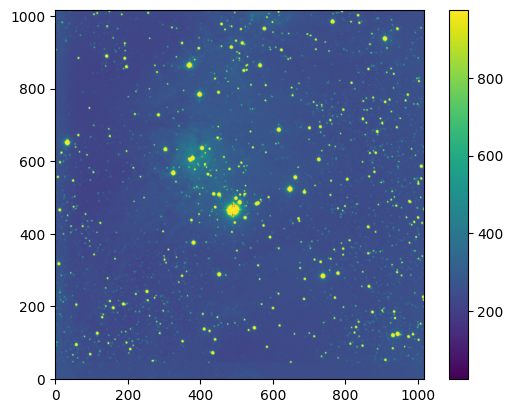

In [116]:
plt.imshow(image, origin='lower', vmin=25, vmax=975)
plt.colorbar()


One can visualize a CCD image as a 3D surface, where the x,y-plane is the pixel coordinates (that map to sky coordinates like RA and Dec) and the z-direction is the number of counts. An image of a star looks like a 'mountain'. To measure the brightness of a star, the goal is to measure the volume of the mountain - the total counts from the star. To do this we must also estimate the height of the 'plain' that the mountain sits on.

Let's display the image as a surface plot to illustrate this.

In [117]:
xarray = np.vstack([np.arange(image.shape[1])]*image.shape[0])
yarray = np.tile(np.arange(image.shape[0])[:,np.newaxis], image.shape[1])

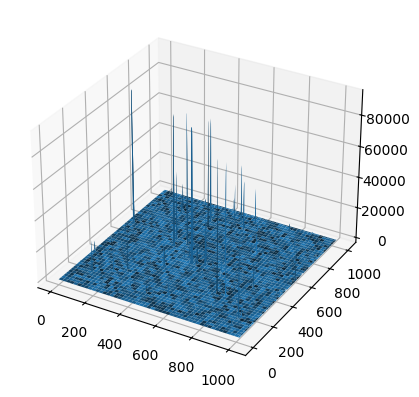

In [118]:
# Plot the surface to visualize the 'mountains'
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
ax.plot_surface(xarray, yarray, image)#, vmin=Z.min() * 2, cmap=cm.Blues)

Zoom in on one star to get a better view of the profile of the star.

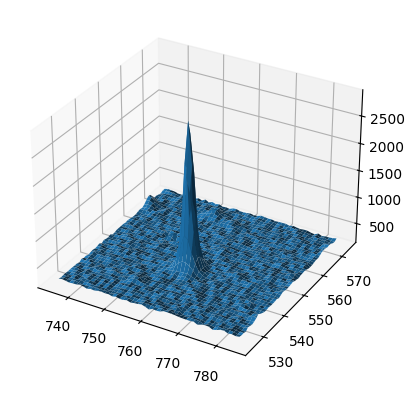

In [119]:
# Plot the surface to visualize the 'mountains'
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
ax.plot_surface(xarray[525:575,735:785], yarray[525:575,735:785], image[525:575,735:785])

# Source detection

We could attempt to identify the stars in our image by hand but this will be slow and painful for any image with more than a few stars. Source detection is clearly a good task to try to automate with a computer. However, the actual implementation of robust, efficient source detection is not straightforward.

Fortunately, there is existing software that we can use. In this example, we use the ```DAOStarFinder```, a time-tested algorithm which identifies local maxima that have a shape that is approximately a 2D Gaussian. For more details on how this works (and a good overview of the full process of aperture photometry), take a look at the original paper: [Stetson 1987](https://ui.adsabs.harvard.edu/abs/1987PASP...99..191S/abstract).

### Estimating the FWHM

Setting up source detection requires that we define two things:

1. The expected width of the star - the FWHM.

2. A noise threshold - the minimum signal above the background that a pixel must have to be considered part of an object.

We know that the seeing can vary during the night, so the best way to estimate the seeing is to measure the FWHM of a star of moderate brightness from the data itself.

As a toy example, we will select a star and take an intensity tracing through it, much like the example drawn on the chalkboard in class.

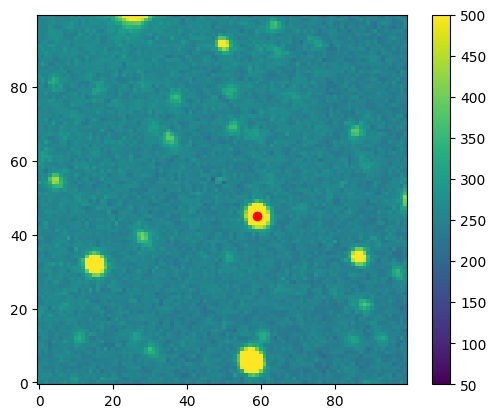

In [120]:
# starting coordinates
xstar = 759
ystar = 545

# show only a portion of the image around the star so it is easier to see the star
plt.imshow(image[500:600,700:800], origin='lower', vmin=50, vmax=500)
# note: we trimmed the image so we have to correct to the new origin
plt.plot([xstar-700], [ystar-500], 'o', color='red')
plt.colorbar()

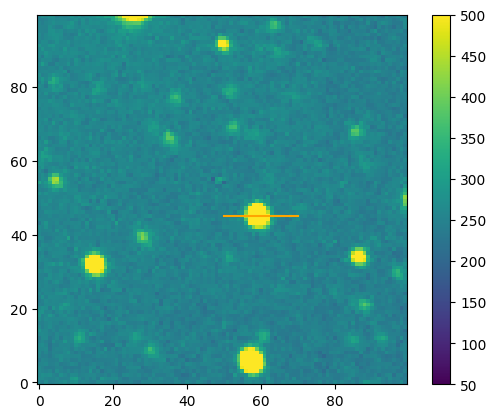

In [121]:
# draw a line on the image to make sure it's where we want it to be
plt.imshow(image[500:600,700:800], origin='lower', vmin=50, vmax=500)
# note: we trimmed the image so the (x,y) values are relative to the new origin
plt.plot([50,70],[ystar-500,ystar-500], color='orange')
plt.colorbar()

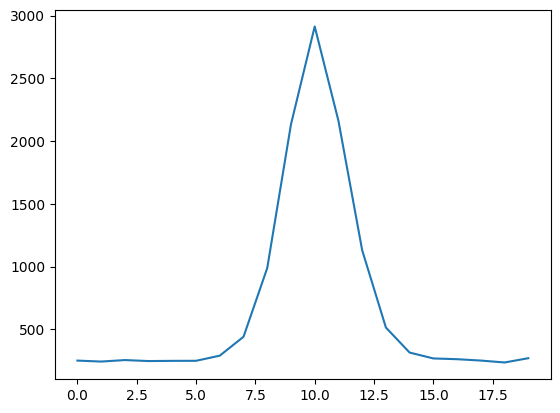

In [122]:
# plot the slice through the star
plt.plot(image[ystar,xstar-10:xstar+10])

This looks similar to what we would expect but be careful! We just eyeballed the position of the star and the location where we took the intensity tracing. This tracing does not necessarily go through the center of the star!

We can do better by calculating the sub-pixel center of the star.
There are a few different ways to do this. One approach is to calculate the center of light (analogous to calculating the center of mass). In one dimension, this is

\begin{equation}
\frac{\Sigma N_i x_i}{\Sigma N_i}
\end{equation}

where $N_i$ is the counts in pixel $i$ and $x_i$ is the pixel coordinate.

In [123]:
# calculate the x and y centroids separately
xcntr = np.sum(np.arange(xstar-10,xstar+10)*image[ystar,xstar-10:xstar+10]) / np.sum(image[ystar,xstar-10:xstar+10])
ycntr = np.sum(np.arange(ystar-10,ystar+10)*image[ystar-10:ystar+10,xstar]) / np.sum(image[ystar-10:ystar+10,xstar])

In [124]:
print(xcntr, ycntr)

758.8837570308 545.0528790741504


Ideally, we would use these precise sub-pixel positions to take a tracing through the true center of the star. This requires interpolating the measured flux to that position. For now, we'll look at the simpler case of the nearest integer pixel.

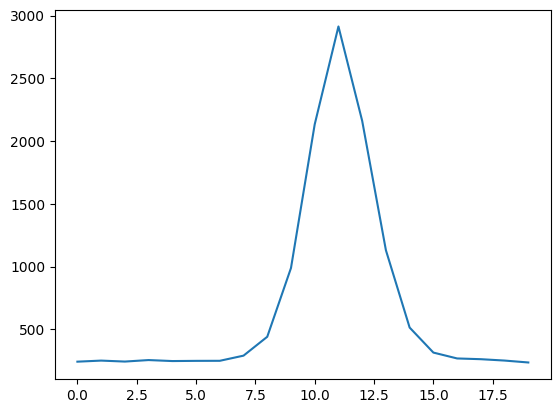

In [125]:
plt.plot(image[ycntr.astype(int),xcntr.astype(int)-10:xcntr.astype(int)+10])

We can also find the center of the star by fitting a model. For example, let's fit a 1D Gaussian model to the radial profile in both the x and y directions.

In [126]:
from astropy.modeling import models, fitting

# Fit the stellar profile with a 1D Gaussian
g_init = models.Gaussian1D(amplitude=1., mean=0, stddev=1.)
fit_g = fitting.TRFLSQFitter()

# define the x-coordinates on either side of the origin
xvals = np.arange(-10,10)
# normalize the star profile so the amplitude is ~1
norm_profile = image[ystar,xstar-10:xstar+10]/image[ystar,xstar-10:xstar+10].max()
# fit the Gaussian
g = fit_g(g_init, xvals, norm_profile)


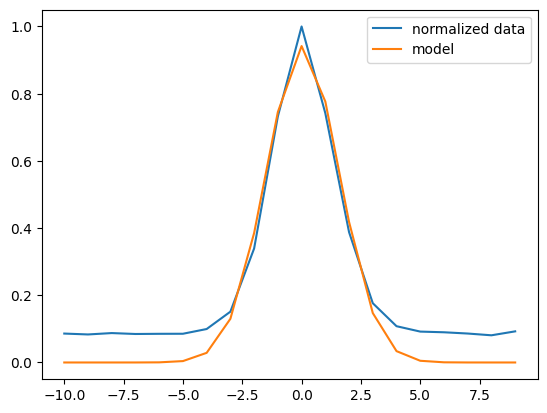

In [127]:
plt.plot(xvals, norm_profile, label='normalized data')
plt.plot(xvals, g(xvals), label='model')
plt.legend()

We can use the results of the Gaussian fit to determine the subpixel center position and the FWHM of the star.

In [128]:
g

<Gaussian1D(amplitude=0.94218373, mean=0.04813015, stddev=1.53161333)>

In [129]:
fwhm = 2 * g.stddev * np.sqrt(2 * np.log(2))
fwhm

np.float64(3.6066737793334522)

Try fitting a 2D Gaussian too. How different is the estimated FWHM?

### Determining the threshold

Next, we need to determine the threshold that the ```DAOstarfinder``` uses to determine if a pixel is part of the background and excluded. Pixels with counts above the threshold value are detected sources. We will use the image statistics to determine the threshold value. We apply sigma clipping so that outliers in the data do not bias the results.

In [130]:
from astropy.stats import sigma_clipped_stats

mean, median, std = sigma_clipped_stats(image, sigma=3.0)
print(f'Sky background: mean = {mean:.5g}, median = {median:.5g}, standard deviation = {std:.3g}')

Sky background: mean = 252.46, median = 249.83, standard deviation = 22


With the value of the FWHM and threshold determined, we can finally search for stars in the image.

### Star finding

In [131]:
# find the stars
from photutils.detection import DAOStarFinder

# use the FWHM calculated above as the estimated FWHM for the data
# set a threshold that detected stars must be at least 5-sigma above the background
daofind = DAOStarFinder(fwhm=fwhm, threshold=5.*std)
sources=daofind.find_stars(image-median)
sources['id', 'xcentroid','ycentroid'].pprint()

 id      x_centroid         y_centroid    
---- ------------------ ------------------
   1   77.5702837069308 45.490446289684904
   2  300.7069338611488  45.63046942995725
   3 422.95007158877524  45.43530809498482
   4   648.035418355692  45.92788716707577
   5  831.2814126893595  45.67286773126147
   6  48.85035746203573  47.31758207713473
   7  440.6321205150178  47.38415381554594
   8 23.318796598053055  48.32948844689851
   9 1001.7421481141815  47.74340206844177
  10  802.2746658630592  48.75811328830828
 ...                ...                ...
1214 148.95334847325753 1011.2396836014483
1215  788.9874158756782 1010.8993331507128
1216 14.382963555599847 1013.8040547193201
1217  44.44942250093362 1016.3343483012576
1218  85.61821688373544 1016.5112993423335
1219 420.83704417448183 1016.1444977834543
1220  821.5552115237773 1016.0820862994949
1221   881.447073408749 1016.3179309569915
1222  57.63881880349348 1016.4310088635337
1223 445.39610462070766 1016.6982245900491
Length = 12

Do a quick visual check to make sure that the detected sources mostly coincide with things that look like stars.

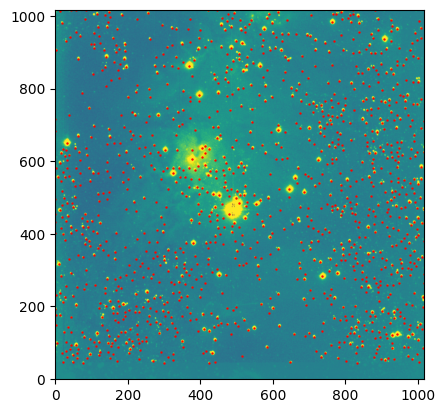

In [132]:
plt.imshow(image, origin='lower', vmin=50, vmax=500)
plt.scatter(sources['xcentroid'], sources['ycentroid'], color='red', s=0.5)

This initial result looks pretty good but be sure to zoom in and inspect the results closely. It is highly unlikely that automatic source detection did a perfect job identifying (only) real objects.

# Centroiding


The results of ```DAOStarFinder``` include the sub-pixel center position of each detected source. In this case, we don't have to recalculate the centroid. However, there may be times when you start from a list of positions that are approximately correct but you will want to compute the centroid to get accurate positions for your data.

One could naively estimate that the brightest pixel in a source represents its center. This can be biased by bad data (an unseen cosmic ray, a saturated stellar core) and gives even worse results for extended objects with variable surface brightness profiles like galaxies.

We've already explored a couple of simple ways to determine the sub-pixel center of a star - computing the center of light and fitting a Gaussian profile. We can perform these same tasks using the ```centroids``` package in ```photutils``` to calculate centroids for all the stars in the image. You can read about some of the different options to compute the centroid in the documentation: https://photutils.readthedocs.io/en/stable/reference/centroids_api.html.

Let's try an example using ```centroid_quadratic```.


In [133]:
from photutils.centroids import centroid_quadratic
xycen = centroid_quadratic(image, xpeak=xstar, ypeak=ystar)
print(xycen)

[759.06280145 545.16449144]


Compare this to the center of light we computed.

In [134]:
print(xcntr,ycntr)

758.8837570308 545.0528790741504


...and the center found by ```DAOStarFinder```.

In [135]:
# calculate the radial distance of our star from all stars detected by DAOStarFinder
rad_dist = np.sqrt((sources['xcentroid'] - xstar)**2 + (sources['ycentroid'] - ystar)**2)
# find the minimum distance
idx = np.argmin(rad_dist)

In [136]:
# print the coordinates to make sure we've selected the correct star
sources['xcentroid','ycentroid'][idx]

x_centroid,y_centroid
float64,float64
759.0610389666143,545.265242599321


(535.0, 555.0)

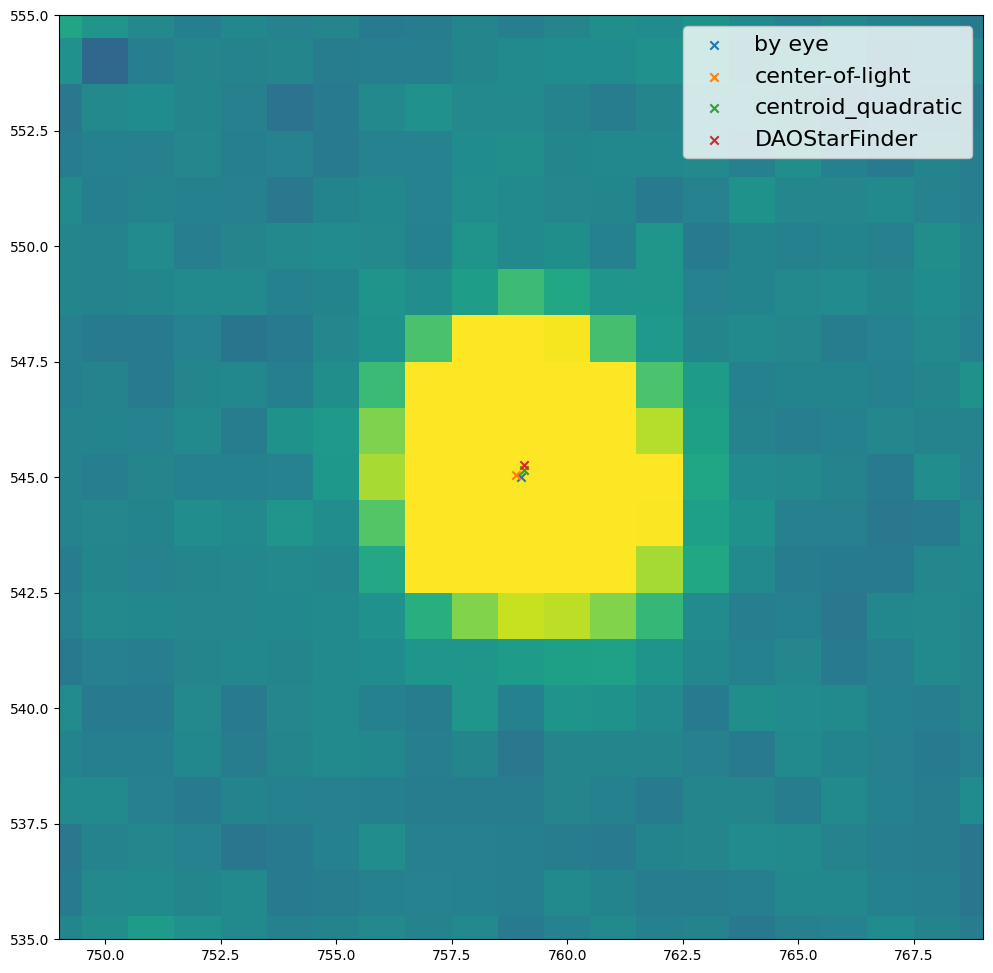

In [137]:
# plot all the centroids on a super-zoomed in image to show the scatter
plt.figure(figsize=(12,12))
plt.imshow(image, origin='lower', vmin=50, vmax=500)
plt.scatter(xstar,ystar, marker='x', label='by eye')
plt.scatter(xcntr,ycntr, marker='x', label='center-of-light')
plt.scatter(xycen[0],xycen[1], marker='x', label='centroid_quadratic')
plt.scatter(sources['xcentroid'][idx],sources['ycentroid'][idx], marker='x', label='DAOStarFinder')
plt.legend(fontsize=16)

plt.xlim(xstar-10, xstar+10)
plt.ylim(ystar-10, ystar+10)

We can also use the centroid position to extract the radial profile of the star.

In [138]:
from photutils.profiles import RadialProfile
edge_radii = np.arange(25)
rp = RadialProfile(image, xycen, edge_radii, mask=None)

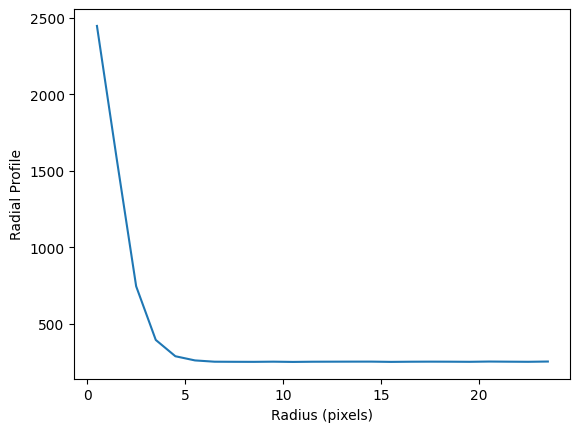

In [139]:
rp.plot(label='Radial Profile')

Look familiar? Note that this is a radial profile, so it's only half the star. From this radial profile, it's easy to get the FWHM from a Gaussian fit.

In [140]:
rp.gaussian_fwhm

np.float64(4.005896322957996)

Note that the FWHM is slightly different from what we calculated above because our simple estimate almost certainly did not go through the center of the star.

# Aperture photometry

Aperture photometry works by adding up all the counts in an aperture centered on the star (the mountain), and subtracting off the ‘average’ height of the background determined from the pixel values in an annulus around the star (the ‘plain’).

Let's go through the process step-by-step for our example star.

### Define the aperture and extract the signal

We'll use a circular aperture for this star-based example. Be sure to look at the documentation for ```photutils.aperture``` to see what other apertures are available: https://photutils.readthedocs.io/en/latest/user_guide/aperture.html

(500.0, 600.0)

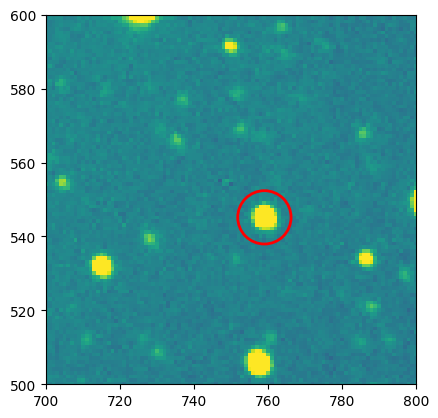

In [141]:
from photutils.aperture import CircularAperture

# Define the aperture
aperture = CircularAperture(xycen, r=2*fwhm)

# Plot the aperture on top of the image
plt.imshow(image, origin='lower', vmin=50, vmax=500)
aperture.plot(color='red', lw=2, label='Aperture')
plt.xlim(700, 800)
plt.ylim(500, 600)

All we did in the previous step was define the aperture. Next, we'll use the ```aperture_photometry``` function to extract the counts.

In [142]:
from photutils.aperture import aperture_photometry

# actually perform aperture photometry
phot_table = aperture_photometry(image - median, aperture)
print(phot_table)


 id      x_center          y_center        aperture_sum   
--- ----------------- ----------------- ------------------
  1 759.0628014482564 545.1644914371024 32111.976200242967


The same basic process can be used to fit multiple apertures at once. Let's do this to make the plot of the number of counts as a function of the aperture size.

In [143]:
# Define the apertures between 0.5 and 5 times the FWHM
radii = np.arange(0.5, 5, 0.25) * fwhm
apertures = [CircularAperture(xycen, r=r) for r in radii]

# Perform aperture photometry
phot_table = aperture_photometry(image - median, apertures)

print(phot_table)
print(phot_table.colnames)

 id      x_center          y_center     ...  aperture_sum_16   aperture_sum_17 
--- ----------------- ----------------- ... ----------------- -----------------
  1 759.0628014482564 545.1644914371024 ... 33760.44592621948 34042.10134909352
['id', 'x_center', 'y_center', 'aperture_sum_0', 'aperture_sum_1', 'aperture_sum_2', 'aperture_sum_3', 'aperture_sum_4', 'aperture_sum_5', 'aperture_sum_6', 'aperture_sum_7', 'aperture_sum_8', 'aperture_sum_9', 'aperture_sum_10', 'aperture_sum_11', 'aperture_sum_12', 'aperture_sum_13', 'aperture_sum_14', 'aperture_sum_15', 'aperture_sum_16', 'aperture_sum_17']


Text(0, 0.5, 'Flux (ADU)')

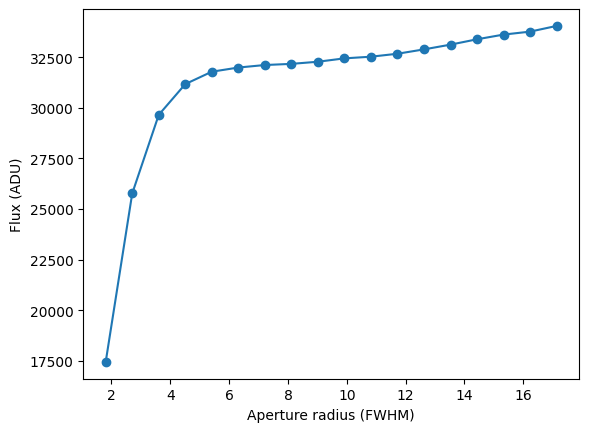

In [144]:
# Get the region we are interested in from the table
region = phot_table[0]

# Convert the values to a list
region_data = list(region.values())

# Exclude the first three values, which are the id, x, and y coordinates
fluxes = region_data[3:]

# Plot the growth curve
plt.plot(radii, fluxes, marker='o')
plt.xlabel('Aperture radius (FWHM)')
plt.ylabel('Flux (ADU)')

This 'growth curve' measures the increase in flux as a function of the aperture size. Notice that it begins to level off but does not go completely flat. This is because each pixel in the aperture includes sky emission which will contribute to the total counts. More pixels, more counts. The next step is to remove the local background to isolate the star light as much as possible.

### Determine the local background

If you looked carefully at the code, you may have noticed that we did source detection on the ```image - median```. This is in essense a very coarse estimate of the background. To provide the best estimate of the sky  contribution to the counts for any given star, we need to measure the (spatially variable) sky emission locally. We do this by estimating a representative value for the sky from an annulus around the star.

The ```photutils.aperture``` package provides an easy way to setup a sky annulus.

(500.0, 600.0)

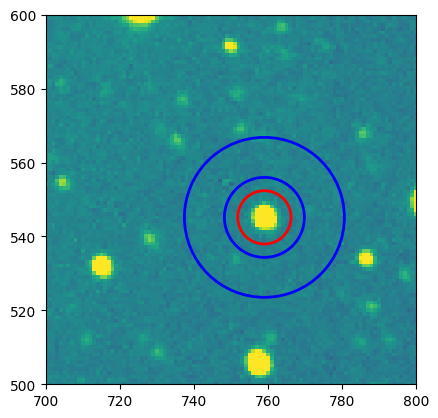

In [145]:
from photutils.aperture import CircularAnnulus

# Define the annulus
annulus = CircularAnnulus(xycen, r_in=3*fwhm, r_out=6*fwhm)

# Plot the annulus
plt.imshow(image, origin='lower', vmin=50, vmax=500)
aperture.plot(color='red', lw=2, label='Aperture')
annulus.plot(color='blue', lw=2, label='Annulus')
plt.xlim(700, 800)
plt.ylim(500, 600)

Ideally, the annuli should be far enough from the star that they do not include any light from the target star but not so far that they no longer represent the local sky emission. (what plot could you use to test your annulus size?)

Next, we use the statistics in the sky annulus to come up with a representative value for the sky background.

In [146]:
from photutils.aperture import ApertureStats

annulus_stats = ApertureStats(image, annulus)
back = annulus_stats.median
std = annulus_stats.std
print(f'Background per pixel: {back:.3f}')

Background per pixel: 251.659


Notice that we are using the median, not the mean! The mean will be affected by outliers - like another star that falls in the sky annulus - more so than the median.

The median value in the annulus gives the expected background emission *per pixel*, so we need to multiply that by the area of the aperture to determine the total amount of sky emission to subtract from the star.

In [147]:
phot_table = aperture_photometry(image, aperture)
flux = phot_table['aperture_sum'][0]
aperture_area = aperture.area_overlap(image)
flux_no_back = flux - back * aperture_area

print(f'Flux (raw): {flux:.3f}')
print(f'Background: {back:.3f}')
print(f'Area: {aperture_area:.3f}')
print(f'Flux (without background): {flux_no_back:.3f}')

Flux (raw): 72950.383
Background: 251.659
Area: 163.465
Flux (without background): 31812.992


A few things to note:
 - the flux (counts) should be lower after you subtract the background.
 - the difference may be even more dramatic in data taken with RUCO as the sky background is significantly higher in the center of Houston than it is in west Texas!

### Performing aperture photometry for many stars at once

Most of the same steps we just performed for our example star can be done for many stars at once.

To start, take a look at the output from ```DAOStarFinder``` again. We only looked at the first three columns earlier but there is a lot more information in the full table.

In [148]:
sources

id,x_centroid,y_centroid,sharpness,roundness1,roundness2,n_pixels,peak,flux,mag,daofind_mag
int64,float64,float64,float64,float64,float64,int64,float64,float64,float64,float64
1,77.5702837069308,45.490446289684904,0.44867264861773887,0.010310846675332656,-0.33236385712819333,25,748.4954458344137,6371.236088411455,-9.510559245790425,-2.3898457441483445
2,300.7069338611488,45.63046942995725,0.5136693032722127,0.05491913959568274,-0.18013735468536457,25,423.40569357044205,3110.3537722119054,-8.732024471426863,-1.721299107483366
3,422.95007158877524,45.43530809498482,0.4591270747300399,-0.12306982005056598,-0.20108768662381238,25,616.5739432811804,4572.489331299314,-9.15038175209435,-2.2456724061843234
4,648.035418355692,45.92788716707577,0.49646427290635164,-0.21647871544663982,-0.2211408992768855,25,5056.2782636662,38135.00713291477,-11.453309579892023,-4.435269425329406
5,831.2814126893595,45.67286773126147,0.5991132010593879,-0.28145021969955486,-0.23002587293625293,25,345.3092082833706,2204.6116869051484,-8.358330263324248,-1.4067551664757265
6,48.85035746203573,47.31758207713473,0.5102490466326649,-0.19337860334579243,0.044019727000865455,25,604.1727763947223,5686.726124776934,-9.387155782357945,-1.9363990986169193
7,440.6321205150178,47.38415381554594,0.5235871866463577,-0.2041697420301203,0.012095335259474333,25,136.5238400045816,1017.8354547633177,-7.519193936985466,-0.46293632581078265
8,23.318796598053055,48.32948844689851,0.5274730125292139,-0.13199399955884777,0.05813287624276055,25,171.75099402127074,1712.2398656516575,-8.083911511004535,-0.48122326366342955
9,1001.7421481141815,47.74340206844177,0.6321065773787493,0.24159636892226274,-0.22850507629622988,25,149.5396722078446,1382.5105654130098,-7.851671147379518,-0.20343138548283277


Notice that there are several other parameters, including sharpess and roundness estimates for all sources. These parameters can be a great way to further filter the list of detected objects to identify things that are/aren't highly likely to be stars. You can also play around with these parameters to see if changing their limits results in a better or worse selection of things that actually look like (single) stars. Better yet, plot out these parameters. Do the sharpness and roundness values tend to cluster around a particular number?

Once you are happy with your list of probable stars, we can go through the same steps we did for one star to perform photometry on many sources at once.

In [149]:
positions = np.transpose((sources['xcentroid'], sources['ycentroid']))

 ...]

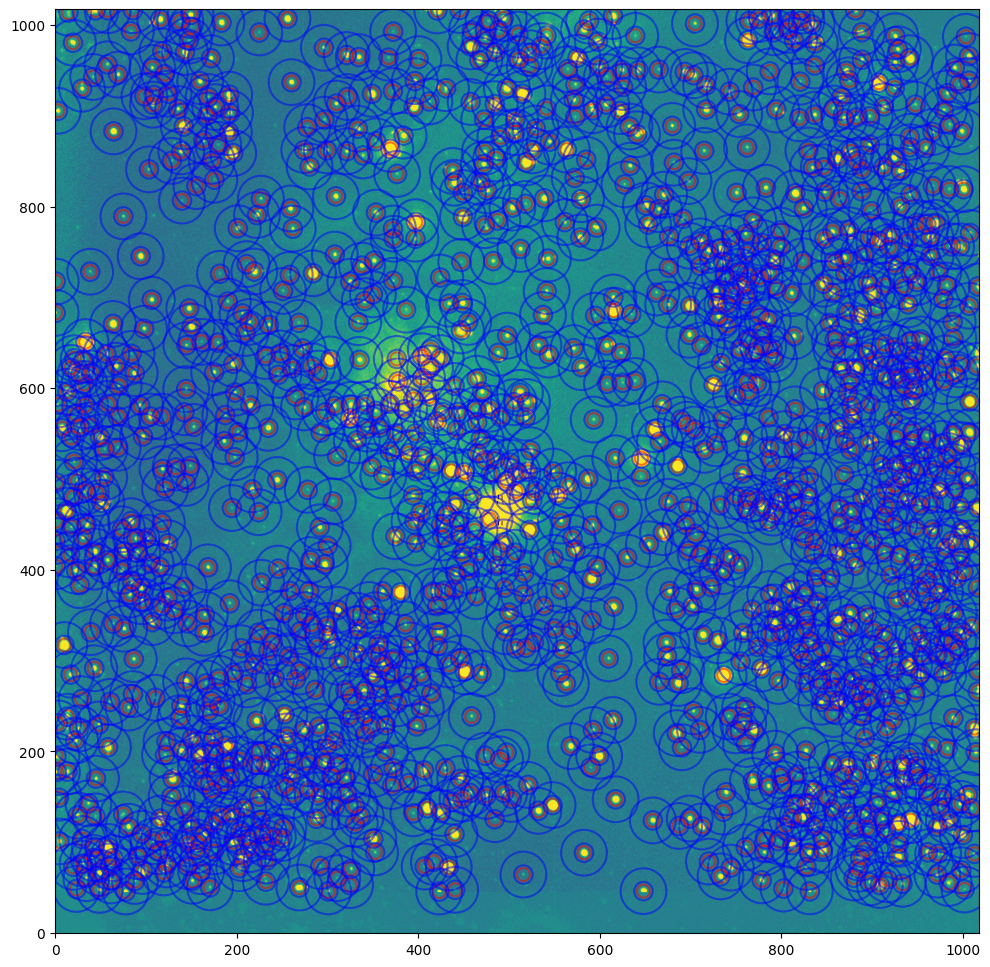

In [150]:
# define the aperture
r_a = 2*fwhm
apertures = CircularAperture(positions, r=r_a)

# define the annulus
r_in = r_a + 3
r_out = r_in + 15
annulus = CircularAnnulus(positions, r_in=r_in, r_out=r_out)

# display the image
plt.figure(figsize=(12,12))
plt.imshow(image, origin='lower', vmin=50, vmax=500)

# plot the aperture and the annulus for each source
apertures.plot(color='red', lw=1.5, alpha=0.5)
annulus.plot(color='blue',lw=1.5, alpha=0.5)

In [151]:
phot_table = aperture_photometry(image, apertures)
phot_table

id,x_center,y_center,aperture_sum
int64,float64,float64,float64
1,77.5702837069308,45.490446289684904,49874.42329417298
2,300.7069338611488,45.63046942995725,44338.53266241025
3,422.95007158877524,45.43530809498482,45515.11037789119
4,648.035418355692,45.92788716707577,83362.34815021144
5,831.2814126893595,45.67286773126147,45681.86239608491
6,48.85035746203573,47.31758207713473,48786.80237219761
7,440.6321205150178,47.38415381554594,39861.37145839927
8,23.318796598053055,48.32948844689851,45818.29878532438
9,1001.7421481141815,47.74340206844177,45729.980022742624


In [152]:
aperstats = ApertureStats(image, annulus)

In [153]:
phot_table['median_bkg'] = aperstats.median
phot_table

id,x_center,y_center,aperture_sum,median_bkg
int64,float64,float64,float64,float64
1,77.5702837069308,45.490446289684904,49874.42329417298,254.21456668214495
2,300.7069338611488,45.63046942995725,44338.53266241025,244.49300688643302
3,422.95007158877524,45.43530809498482,45515.11037789119,244.49300688643302
4,648.035418355692,45.92788716707577,83362.34815021144,244.49300688643302
5,831.2814126893595,45.67286773126147,45681.86239608491,252.38700929830344
6,48.85035746203573,47.31758207713473,48786.80237219761,263.75294598430673
7,440.6321205150178,47.38415381554594,39861.37145839927,244.49300688643302
8,23.318796598053055,48.32948844689851,45818.29878532438,272.66087881083513
9,1001.7421481141815,47.74340206844177,45729.980022742624,272.66087881083513


In [154]:
bkg_contribution = phot_table['median_bkg'] * apertures.area
source_counts = phot_table['aperture_sum'] - bkg_contribution

In [155]:
phot_table['bkg_tot'] = bkg_contribution
phot_table['src_counts'] = source_counts

From here, you should be able to calculate instrumental magnitudes. Don't forget to divide by the exposure time to get the count rate instead of the total number of counts!

To flux calibrate the data, you'll want to correct for atmospheric extinction. Recall that the extinction correction is $k\sec{z}$. For this exercise, assume that $k=1$. You can look up the airmass of observation in the image header. Note that it's always a good idea to make note to the airmass in your observing log too because header information can be wrong!

In [156]:
header = fits.open('/content/drive/MyDrive/my_ASTR229_data/m82/obj0068.fits')[0].header

In [157]:
header['EXPTIME']

60.0

In [158]:
header['AIRMASS']

1.311

# Your turn

Use your fully reduced V band image of M82 for the following photometry exercise. For this assignment, submit your documented code and be sure to answer the following questions.

Each question will be evaluated based on the following three criteria, each of equal weight:

 - **Presentation:** Unreadable figures will lose at least 50% of the presentation credit.

  - **Process:** show your work and use the correct tools.

  - **Outputs:** answers are correct, include appropriate labels and units.

1. Measure the FWHM of at least three different stars. Explain how different the values you find are and what property is responsible for the difference.

In [159]:
# your answer here

2. Make the growth curve showing the number of counts as a function of aperture size. Label the radii you would choose for your aperture and the inner and outer radii of your sky annulus. Explain your reasoning.

In [160]:
# your answer here

3. Compute the instrumental magnitudes for the stars in your image. State what the "typical" (or median) magnitude is.

In [161]:
# your answer here

4. Find one or more stars in your image with a known V band magnitude. Use these stars to flux-calibrate your data.

In [162]:
# your answer here

5. Imagine that you want to repeat this process on the B band image. Which steps will you have to redo for a different filter and which can you use again?

In [163]:
# your answer here

6. For any steps where you can use the results from the V band image, can you directly apply those results or do you need to do any additional steps to apply those results to the B band? If none of the steps can be applied, explain why not.

In [164]:
# your answer here

7. Of the many parameters output by the DAOStarFinder, which do you think are most useful to identify things that are not stars (spurious sources) that you will want to remove from your catalog? Explain your reasoning.

In [165]:
# your answer here